In [1]:
import bohnasa
import matplotlib.pyplot as plt 
import numpy as np


In [27]:
N = 1000
L = 2
fock = bohnasa.fockStates_fixed_particle_number(N,L)

f = np.zeros(L)
f[0] = N


sta1 = bohnasa.single_fockstate(fock, f)
f = np.zeros(L)
f[-1] = N
sta2 = bohnasa.single_fockstate(fock, f)


sta = np.random.rand(fock.dim) #sta1 #+sta2
sta *= 1/np.linalg.norm(sta)
phi = np.full(L,1j,dtype=complex)*(-1)**np.arange(L)
#phi = np.random.rand(L)-0.5 + 1j*(np.random.rand(L)-0.5)
sta = bohnasa.coherent_state_number_projected(fock,phi)
print(sta,np.linalg.norm(sta))
hopping = bohnasa.hopping(fock)
hopping.matrix *= -1
interaction = bohnasa.interaction(fock)
interaction.matrix *= 4
test_op = hopping + interaction

def gs(X, row_vecs=True, norm = True):
    if not row_vecs:
        X = X.T
    Y = X[0:1,:].copy()
    print(X.shape)
    for i in range(1, X.shape[0]):
        proj = np.diag((X[i,:].dot(Y.T)/np.linalg.norm(Y,axis=1)**2).flat).dot(Y)
        newT = X[i,:] - proj.sum(0)
        newT *= 1/np.linalg.norm(newT)
        print("newT",newT)
        Y = np.vstack((Y, newT))
        
    if norm:
        Y = np.diag(1/np.linalg.norm(Y,axis=1)).dot(Y)
    if row_vecs:
        return Y
    else:
        return Y.T
"""
def lanzos(sta,op,krylov_dim,beta_tol=1e-8):

    v = np.zeros((krylov_dim + 1, sta.shape[0]), dtype=complex)
    T_m = np.zeros((krylov_dim+1,krylov_dim+1),dtype=complex)
    v[0] = sta/np.linalg.norm(sta)

    w_prime = op(v[0])

    alpha = np.vdot(w_prime, v[0, :])

    w = w_prime - alpha * v[0, :]

    T_m[0, 0] = alpha

    for j in range(1, krylov_dim + 1):

        beta = np.linalg.norm(w)

        if beta < beta_tol:

            # Happy breakdown
            v_happy = v[0:j, :]
            T_m_happy = T_m[0:j, 0:j]

            return v_happy, T_m_happy

        v[j, :] = w / beta
        w_prime = op(v[j, :])
        alpha = np.vdot(w_prime, v[j, :])

        w = w_prime - alpha * v[j, :] - beta * v[j - 1, :]

        T_m[j, j] = alpha
        T_m[j, j - 1] = beta
        T_m[j - 1, j] = beta

    return v, T_m

"""

[ 3.05493636e-151+4.90953700e-164j -9.66055702e-150-9.51319500e-163j
  2.15908587e-148+7.82471707e-162j ...  2.15908587e-148-7.82471707e-162j
 -9.66055702e-150+9.51319500e-163j  3.05493636e-151-4.90953700e-164j] 0.9999999999999021


'\ndef lanzos(sta,op,krylov_dim,beta_tol=1e-8):\n\n    v = np.zeros((krylov_dim + 1, sta.shape[0]), dtype=complex)\n    T_m = np.zeros((krylov_dim+1,krylov_dim+1),dtype=complex)\n    v[0] = sta/np.linalg.norm(sta)\n\n    w_prime = op(v[0])\n\n    alpha = np.vdot(w_prime, v[0, :])\n\n    w = w_prime - alpha * v[0, :]\n\n    T_m[0, 0] = alpha\n\n    for j in range(1, krylov_dim + 1):\n\n        beta = np.linalg.norm(w)\n\n        if beta < beta_tol:\n\n            # Happy breakdown\n            v_happy = v[0:j, :]\n            T_m_happy = T_m[0:j, 0:j]\n\n            return v_happy, T_m_happy\n\n        v[j, :] = w / beta\n        w_prime = op(v[j, :])\n        alpha = np.vdot(w_prime, v[j, :])\n\n        w = w_prime - alpha * v[j, :] - beta * v[j - 1, :]\n\n        T_m[j, j] = alpha\n        T_m[j, j - 1] = beta\n        T_m[j - 1, j] = beta\n\n    return v, T_m\n\n'

In [28]:
numbVec = fock.dim-1
v, T_m = bohnasa.lanczos(sta,test_op,numbVec,1e-5)

np.linalg.norm(v,axis=1),v.shape


np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all()


index 4 norm of difference 2.156798606605686e-12
repeat
index 7 norm of difference 4.6136169610438295e-12
repeat
index 7 norm of difference 1.235363912518626e-12
repeat
index 7 norm of difference 1.0234775561474884e-12
repeat
index 8 norm of difference 2.1334749109800207e-12
repeat
index 8 norm of difference 1.4372669932760262e-12
repeat
index 9 norm of difference 3.716675112458106e-12
repeat
index 9 norm of difference 1.3760334737651425e-12
repeat
index 10 norm of difference 4.3066158752653365e-12
repeat
index 10 norm of difference 3.31384212747857e-12
repeat
index 10 norm of difference 1.2279033727070299e-12
repeat
index 11 norm of difference 5.765848027506918e-12
repeat
index 11 norm of difference 2.7349779946431676e-12
repeat
index 11 norm of difference 1.4572447673936557e-12
repeat
index 12 norm of difference 6.664421189767782e-12
repeat
index 13 norm of difference 4.618418466879921e-12
repeat
index 13 norm of difference 2.8335246973109607e-12
repeat
index 13 norm of difference 1.

KeyboardInterrupt: 

In [15]:
print(v,v.shape)

[[ 8.88178420e-16-8.72362948e-31j -8.88178420e-15+0.00000000e+00j
   6.24888909e-14+0.00000000e+00j ...  6.24888909e-14+0.00000000e+00j
  -8.88178420e-15+0.00000000e+00j  8.88178420e-16+8.72362948e-31j]
 [ 6.24888909e-14-6.07562124e-29j -5.99893352e-13+6.19961351e-32j
   4.04831724e-12+0.00000000e+00j ...  4.04831724e-12+0.00000000e+00j
  -5.99893352e-13-6.19961351e-32j  6.24888909e-14+6.07562124e-29j]
 [ 1.75877830e-12-1.69274023e-27j -1.61807603e-11+3.45384141e-30j
   1.04542415e-10-2.58290054e-33j ...  1.04542415e-10+2.58290054e-33j
  -1.61807603e-11-3.45384141e-30j  1.75877830e-12+1.69274023e-27j]
 ...
 [-7.57638868e-18-5.21938772e-31j  6.05563813e-18+1.28241082e-32j
  -4.70041646e-18-2.23468696e-34j ... -4.69196343e-18+2.23492419e-34j
   6.07790022e-18-1.28253811e-32j -7.51207794e-18+5.21987383e-31j]
 [-7.06023057e-18-6.38422195e-31j  1.14163157e-17+1.58556221e-32j
   9.83416770e-18-2.79657452e-34j ...  9.83909440e-18+2.79685647e-34j
   1.14329286e-17-1.58571553e-32j -6.98202707e-

(np.True_, np.float64(3.313839504335416e-11))

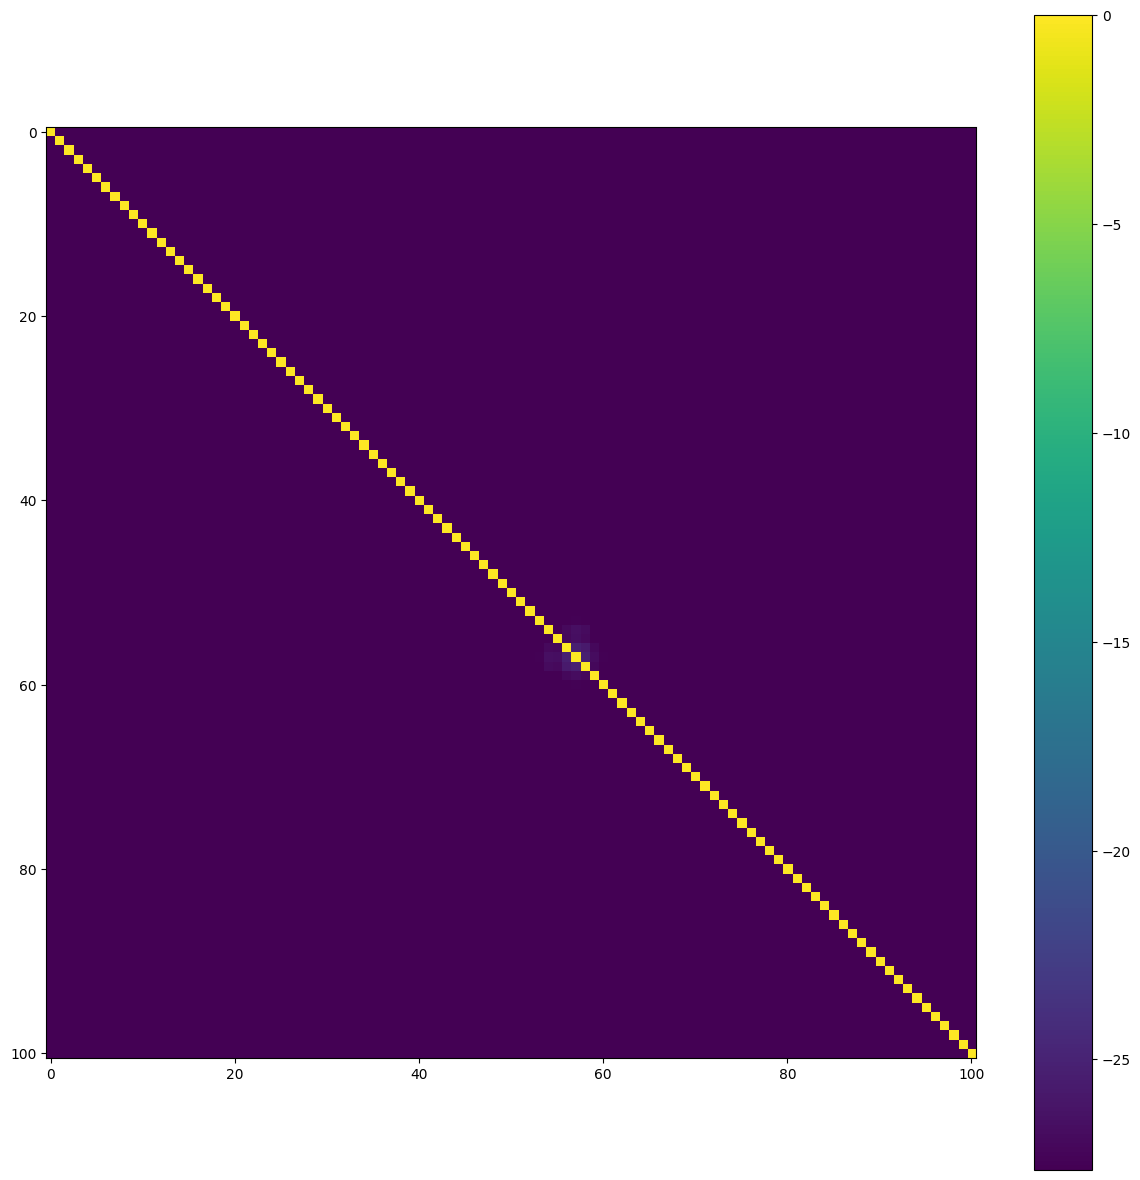

In [16]:
plt.figure(figsize=(15,15))
#plt.imshow(np.log(v@v.T).real)
plt.imshow(np.log(v@v.T +1e-12).real)
##plt.imshow(T_m.real,vmin=-3)
plt.colorbar()

np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all(),np.linalg.norm(np.eye(N=v.shape[0])-(v@v.T))


In [21]:
time = np.linspace(0,0.5,100)
ob = [test_op,bohnasa.number(fock,0),bohnasa.Krylov_complexity(fock,test_op,sta,numbVec)]

index 29 norm of difference 1.503373097294511e-12
repeat
index 31 norm of difference 2.0679860803440885e-12
repeat
index 34 norm of difference 1.0975183032923836e-12
repeat
index 40 norm of difference 1.138662417080201e-12
repeat
index 64 norm of difference 1.0344403821928976e-12
repeat


In [22]:

res = bohnasa.time_evolution_exact_ind(test_op,sta,time,ob)

(101,)
(101,)


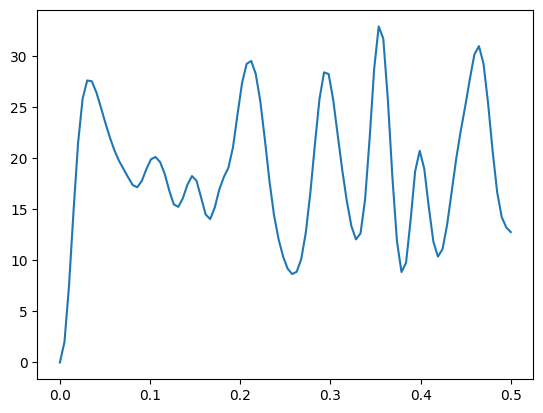

In [23]:
plt.plot(time,res[2,0])


(0.001, np.float64(37.850775862095624))

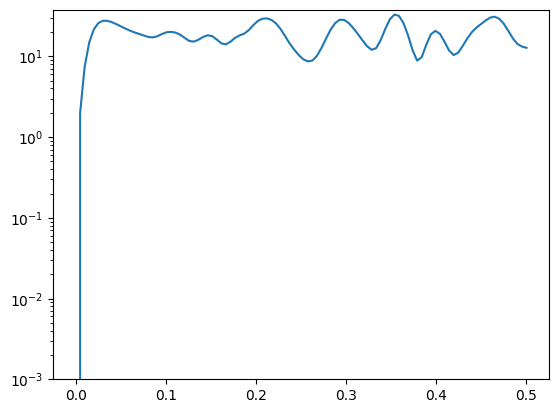

In [24]:
plt.semilogy(time,res[2,0])
plt.ylim(1e-3,None)

/tmp/ipykernel_24084/2761900284.py:1: RuntimeWarning: invalid value encountered in log
  plt.plot(time,np.gradient(np.log(res[2,0]),time))


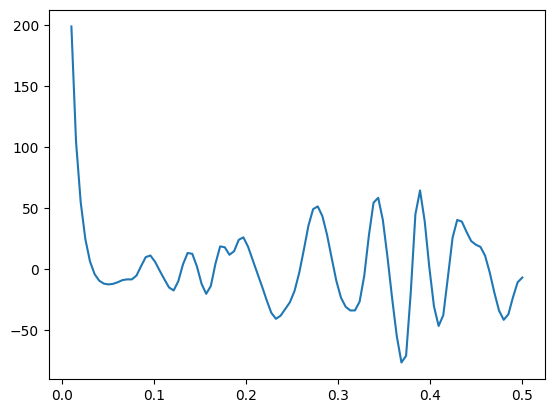

In [26]:
plt.plot(time,np.gradient(np.log(res[2,0]),time))
#plt.ylim(0,10)

In [11]:
sta

array([ 8.88178420e-16-8.72362948e-31j, -8.88178420e-15+0.00000000e+00j,
        6.24888909e-14+0.00000000e+00j, -3.57153760e-13-0.00000000e+00j,
        1.75877830e-12+0.00000000e+00j, -7.70658038e-12+0.00000000e+00j,
        3.06653475e-11+0.00000000e+00j, -1.12373213e-10-0.00000000e+00j,
        3.83141573e-10+0.00000000e+00j, -1.22498829e-09+0.00000000e+00j,
        3.69532494e-09+0.00000000e+00j, -1.05700622e-08-0.00000000e+00j,
        2.87860400e-08+0.00000000e+00j, -7.48947862e-08+0.00000000e+00j,
        1.86701236e-07+0.00000000e+00j, -4.47044535e-07-0.00000000e+00j,
        1.03038674e-06+0.00000000e+00j, -2.29042167e-06+0.00000000e+00j,
        4.91833648e-06+0.00000000e+00j, -1.02175874e-05-0.00000000e+00j,
        2.05624981e-05+0.00000000e+00j, -4.01338867e-05+0.00000000e+00j,
        7.60524879e-05+0.00000000e+00j, -1.40054417e-04-0.00000000e+00j,
        2.50862965e-04+0.00000000e+00j, -4.37394525e-04+0.00000000e+00j,
        7.42877664e-04+0.00000000e+00j, -1.22984754